# Cleaning

This notebook checks the two downloaded block-level files and keeps only true event-count columns for model input.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

root = Path.cwd()
if not (root / 'datasets').exists():
    root = root.parent
raw = root / 'datasets' / 'hdfs_v1' / 'preprocessed'
processed = root / 'datasets' / 'processed'
figures = root / 'reports' / 'figures'

labels = pd.read_csv(raw / 'anomaly_label.csv')
matrix = pd.read_csv(raw / 'Event_occurrence_matrix.csv')
print(labels.shape)
print(matrix.shape)
display(labels.head())
display(matrix.head())


(575061, 2)
(575061, 32)


,BlockId,Label
0,blk_-1608999687919862906,Normal
1,blk_7503483334202473044,Normal
2,blk_-3544583377289625738,Anomaly
3,blk_-9073992586687739851,Normal
4,blk_7854771516489510256,Normal


,BlockId,Label,Type,E1,E2,E3,E4,E5,E6,E7,...,E20,E21,E22,E23,E24,E25,E26,E27,E28,E29
0,blk_-1608999687919862906,Success,NaN,0,0,203,0,10,7,0,...,0,10,1,10,0,4,10,0,0,0
1,blk_7503483334202473044,Success,NaN,0,2,1,0,3,0,0,...,0,3,1,3,0,0,3,0,0,0
2,blk_-3544583377289625738,Fail,21.0,0,0,203,0,3,0,0,...,1,3,1,3,0,0,3,0,0,0
3,blk_-9073992586687739851,Success,NaN,0,3,0,0,3,0,0,...,0,3,1,3,0,0,3,0,0,0
4,blk_7854771516489510256,Success,NaN,0,3,1,15,3,0,0,...,0,3,1,3,0,0,3,0,0,0


The matrix contains block IDs, labels, one extra field, and event counts. Only columns named E followed by a number are features.

In [2]:
event_columns = []
for name in matrix.columns:
    if name.startswith('E') and name[1:].isdigit():
        event_columns.append(name)
print(event_columns)
print(labels.Label.value_counts())
print(matrix.BlockId.duplicated().sum())
print((matrix[event_columns] < 0).sum().sum())


['E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8', 'E9', 'E10', 'E11', 'E12', 'E13', 'E14', 'E15', 'E16', 'E17', 'E18', 'E19', 'E20', 'E21', 'E22', 'E23', 'E24', 'E25', 'E26', 'E27', 'E28', 'E29']
Label
Normal     558223
Anomaly     16838
Name: count, dtype: int64
0
0


The label file is joined by BlockId. The binary target is 0 for Normal and 1 for Anomaly.

In [3]:
df = matrix[['BlockId'] + event_columns].merge(labels, on='BlockId', how='inner')
df['target'] = 0
df.loc[df['Label'] == 'Anomaly', 'target'] = 1
print(df.shape)
print(df.target.value_counts())
print(df[event_columns].isna().sum().sum())


(575061, 32)
target
0    558223
1     16838
Name: count, dtype: int64
0


The class plot shows the imbalance. This is why later notebooks use precision, recall, F1, AUC, log loss, and confusion matrices instead of accuracy alone.

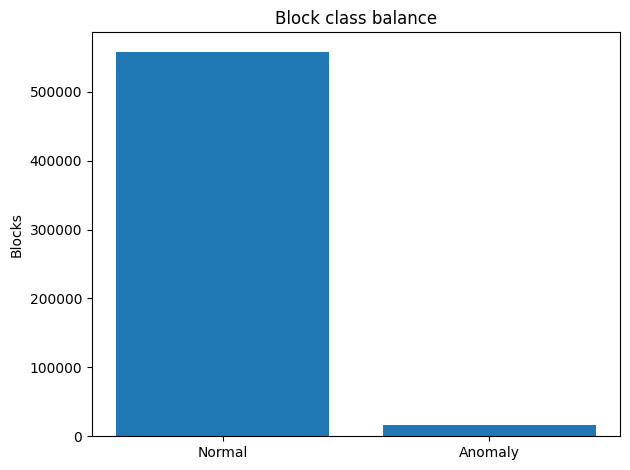

In [4]:
counts = df.target.value_counts().sort_index()
plt.bar(['Normal', 'Anomaly'], counts.values)
plt.title('Block class balance')
plt.ylabel('Blocks')
plt.tight_layout()
plt.savefig(figures / 'class_balance.png', dpi=160)
plt.show()


Total event counts provide a simple view of the log history size for each block.

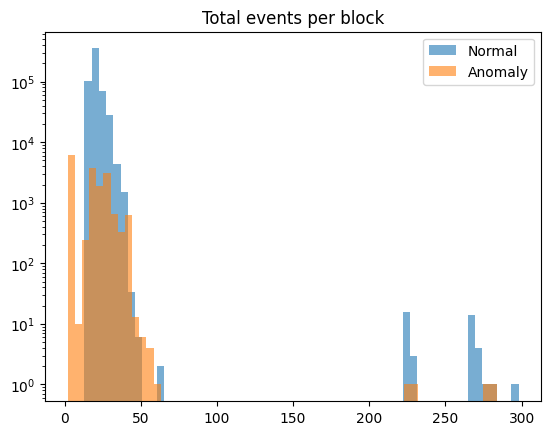

In [5]:
df['total_events'] = df[event_columns].sum(axis=1)
normal = df.loc[df.target == 0, 'total_events']
anomaly = df.loc[df.target == 1, 'total_events']
plt.hist(normal, bins=60, alpha=0.6, label='Normal')
plt.hist(anomaly, bins=60, alpha=0.6, label='Anomaly')
plt.yscale('log')
plt.legend()
plt.title('Total events per block')
plt.show()


The saved split is reused exactly as before. It was made with an 80/20 stratified train/test split and a stratified validation split from the training portion.

In [6]:
splits = np.load(processed / 'splits.npz')
print(len(splits['train_idx']))
print(len(splits['validation_idx']))
print(len(splits['test_idx']))
print(df.target.iloc[splits['test_idx']].mean())


345036
115012
115013
0.029283646196516914


The checks show that IDs are kept only for alignment. Event counts are the only inputs passed to models.